## PedroNetto_MachinLearningforBusiness_CA1

Student Full Name: Pedro Henrique Rodrigues de Andrade Netto

Student Number: 2026083

Module Title: Machine Learning for Business

Assessment Title: CA 1

Lecturer/Supervisor: Dr. Muhammad Iqbal

Date of Submission: Friday 30th October 2026@23:59 (IST)

## 1. Understanding Bike-Sharing Demand Through Clustering and Time-Series Forecasting

### Introduction
In this project, I'm using the Bike Sharing Dataset to explore rental patterns and understand how machine learning techniques can assist in analyzing demand.

The project will focus on two main approaches: clustering and time-series forecasting. These methods can help identify patterns in historical data and investigate how past information can be used to predict future demand.

### Research Question
How does the demand for bike-sharing vary over time and under different conditions, and in what way can historical data help predict future rentals?

### Dataset Overview
The Bike Sharing Dataset is from the UCI Machine Learning Repository.

The dataset contains information on bike rentals, including dates, times, and environmental conditions such as temperature, humidity, and wind speed.

This dataset was selected because it provides real-world transportation data, which can be explored using both clustering techniques and time-series forecasting.

By analyzing these records, I hope to gain a better understanding of rental behavior and investigate how data analysis can support planning and decision-making in a bike-sharing business.

## 2. Load and validate the dataset

Before starting my analysis, I checked the number of rows ans columns, data types, missing values and duplicate records. This helps me understand if my data is able to work on it and whether any cleaning is needed.

In [1]:
import pandas as pd

In [2]:
#reading the data
df = pd.read_csv("hour.csv")

#preview records
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
#checking data size
print("Dataset shape:", df.shape)

Dataset shape: (17379, 17)


In [4]:
#checking data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [5]:
#checking missing values and duplicate rows
print("Missing values by column:\n", df.isnull().sum())

print("\n Number of duplicated rows:", df.duplicated().sum())

Missing values by column:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

 Number of duplicated rows: 0


## 3. Preparation data and inspect variables

I convert the dat column into a datetime format so I can organise the observations by date. I keep the original data and use a separate copy for the analysis.

In [6]:
#Making a copy
data = df.copy()

In [7]:
#converting date column to datetime
data["dteday"] = pd.to_datetime(data["dteday"])

#sort records by date and hour
data = data.sort_values(["dteday", "hr"]).reset_index(drop=True)

In [8]:
print("Start date:", data["dteday"].min())
print("End date:", data["dteday"].max())
print("Rows after sorting:", data.shape[0])

Start date: 2011-01-01 00:00:00
End date: 2012-12-31 00:00:00
Rows after sorting: 17379


In [9]:
data.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


## 4. Exploratory data analysis
### 4.1 Hourly rental demand over time

This chart shows how rental demand changes during the two years. Because there are many hourly observations, I focus on the general patterns rather than each individual change.

<function matplotlib.pyplot.show(close=None, block=None)>

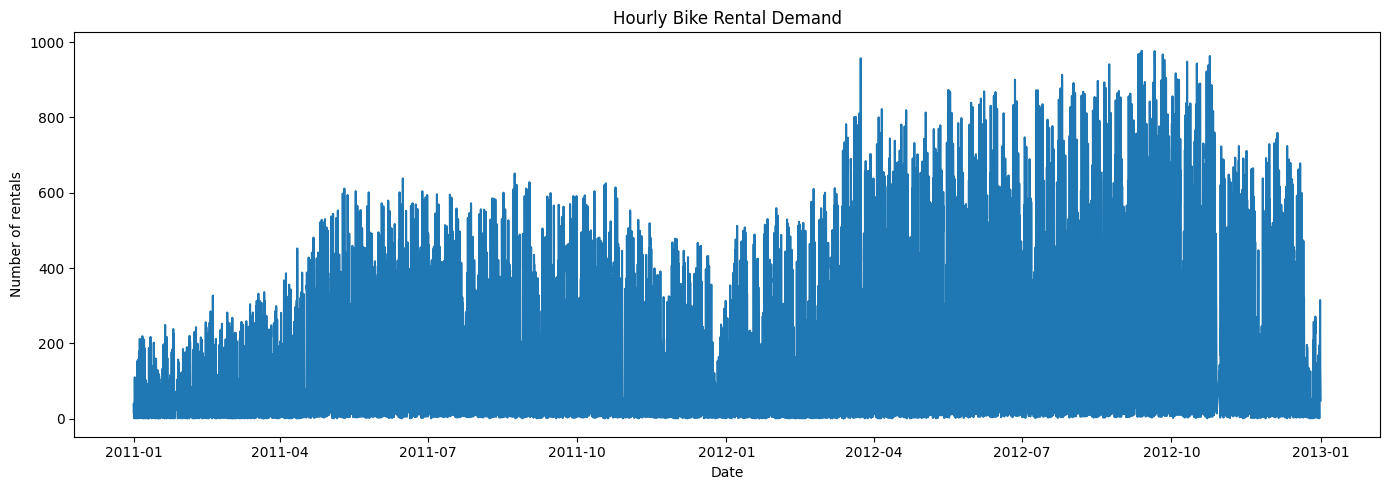

In [10]:
import matplotlib.pyplot as plt

#plot hourly rental count
plt.figure(figsize=(14, 5))
plt.plot(data["dteday"] + pd.to_timedelta(data["hr"], unit="h"), data["cnt"])
plt.title("Hourly Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

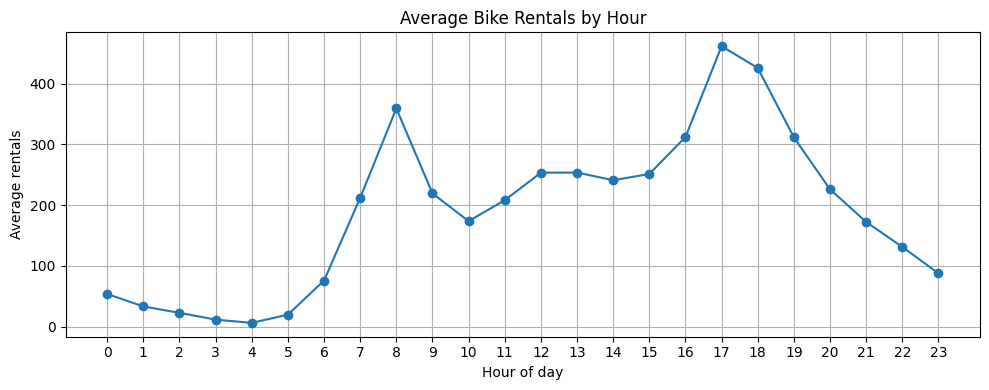

In [11]:
#average rentals by hour of day
hourly_profile = data.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 4))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

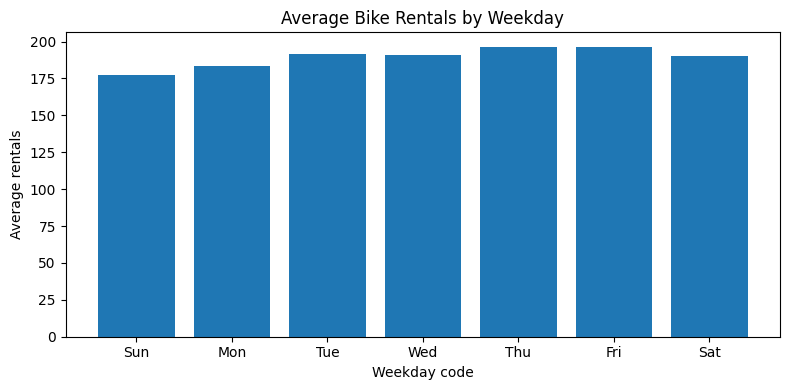

In [12]:
#average rentals by weekday (0=Sunday in this dataset)
weekday_profile = data.groupby("weekday")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weekday_profile.index, weekday_profile.values)
plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Weekday code")
plt.ylabel("Average rentals")
plt.xticks(range(7), ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

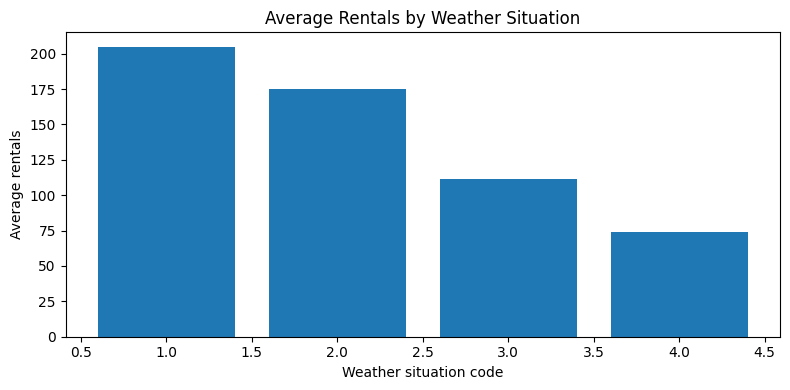

In [13]:
# Average rentals by weather situation
weather_profile = data.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weather_profile.index, weather_profile.values)
plt.title("Average Rentals by Weather Situation")
plt.xlabel("Weather situation code")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show

### Interpretation

The hourly plots show that rental demand changes a lot across the day, rather than staying at one level. The weekday and weather charts help me compare average rentals under different conditions. These are descriptive comparisons: they do not prove that the weather or the day itself caused the change in demand.


## 5. Clustering: selecting the input variables

I chose K-Means because it is a simple method for grouping numerical observations and works well with a dataset of this size. I also chose Agglomerative Clustering because it builds groups in a different, hierarchical way. Comparing the two methods helps me see whether they give similar results on the same data. Other methods, such as DBSCAN or Gaussian Mixture Models, could be considered in future work, but I did not test them here.

I use `hr`, `temp`, `hum`, `windspeed` and `cnt`. I leave out `casual` and `registered` because together they make up `cnt`. I standardise the variables so that features with larger numerical scales do not dominate the distance calculations. Because `cnt` is included, these are descriptive demand profiles, not independent predictions of demand.

In [14]:
# selecting numeric features for clustering
cluster_features = ["hr", "temp", "hum", "windspeed", "cnt"]

X_cluster = data[cluster_features].copy()

#checking the selected features
X_cluster.head()

,hr,temp,hum,windspeed,cnt
0,0,0.24,0.81,0.0,16
1,1,0.22,0.80,0.0,40
2,2,0.22,0.80,0.0,32
3,3,0.24,0.75,0.0,13
4,4,0.24,0.75,0.0,1


In [15]:
X_cluster.describe()

,hr,temp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,11.546752,0.496987,0.627229,0.190098,189.463088
std,6.914405,0.192556,0.192930,0.122340,181.387599
min,0.000000,0.020000,0.000000,0.000000,1.000000
25%,6.000000,0.340000,0.480000,0.104500,40.000000
50%,12.000000,0.500000,0.630000,0.194000,142.000000
75%,18.000000,0.660000,0.780000,0.253700,281.000000
max,23.000000,1.000000,1.000000,0.850700,977.000000


In [16]:
from sklearn.preprocessing import StandardScaler

# standardise features because they are measured on different scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (17379, 5)


### 5.1 Selecting the number of cluster

The two measures evaluate the same idea, compact and well-separated clusters, but they compute it differently. The Silhouette Score works at the level of each observation: it compares the mean distance to the other points in its own cluster (a) with the mean distance to the points in the nearest other cluster (b), as s = (b − a) / max(a, b). The scores are then averaged. It is bounded between −1 and 1, which makes it easy to interpret, but it needs all pairwise distances, so it becomes expensive on large datasets (Rousseeuw, 1987). The Davies-Bouldin Index works at the level of the clusters: for each cluster it finds the most similar other cluster, using the ratio between the average spread around the centroids and the distance between the centroids, and averages these worst-case ratios. It is cheap to compute, it has a lower bound of 0 but no upper bound, and lower values are better (Davies and Bouldin, 1979).

Both measures reward convex, roughly spherical clusters, so they suit K-Means better than density-based or elongated structures. In this project they do not agree: the Silhouette Score is highest for k = 2 (0.248), while the Davies-Bouldin Index is lowest for k = 4 (1.372). This is possible because the Silhouette penalises individual points that sit close to a neighbouring cluster, whereas the Davies-Bouldin Index only looks at centroid distances and average spread. All Silhouette values are around 0.24, which is usually read as weak cluster structure (Kaufman and Rousseeuw, 1990), so I treat the four clusters as descriptive demand profiles and not as sharply separated groups.

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import random
random.seed(42)

# evaluating K-means for several values of K using same reproducible sample
# a sample keeps silhouette calculations manageable while preserving comparability
sample_size = min(5000, len(X_scaled))
sample_indices = data.sample(n=sample_size, random_state=42).index
X_scaled_sample = X_scaled[sample_indices]

k_results = []

for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = model.fit_predict(X_scaled_sample)

    sil = silhouette_score(X_scaled_sample, sample_labels)
    dbi = davies_bouldin_score(X_scaled_sample, sample_labels)

    k_results.append({
        "k": k,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    })

k_results_df = pd.DataFrame(k_results)

In [18]:
#showing the metric winners
best_silhouette_k = int(k_results_df.loc[k_results_df["Silhouette Score"].idxmax(), "k"])
best_dbi_k = int(k_results_df.loc[k_results_df["Davies-Bouldin Index"].idxmin(), "k"])

display(k_results_df)

print("Best k by Silhouette Score:", best_silhouette_k)
print("Best k by Davies-Bouldin Index:", best_dbi_k)

,k,Silhouette Score,Davies-Bouldin Index
0,2,0.247803,1.557757
1,3,0.242677,1.526931
2,4,0.241434,1.364136
3,5,0.213892,1.427984
4,6,0.205395,1.510451


Best k by Silhouette Score: 2
Best k by Davies-Bouldin Index: 4


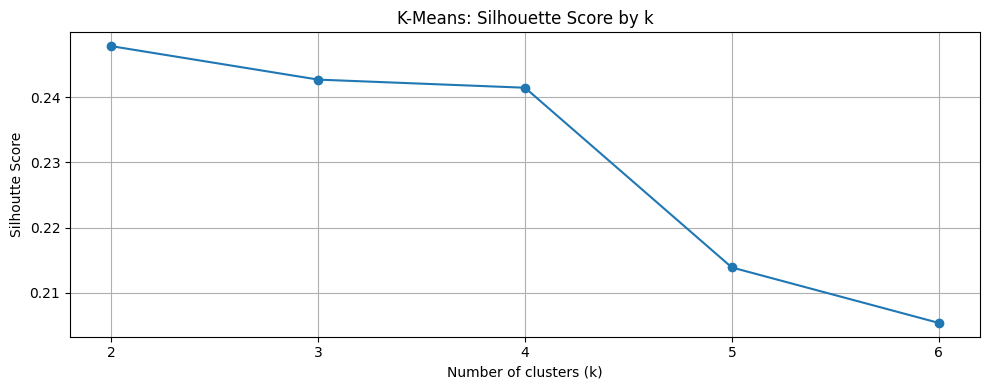

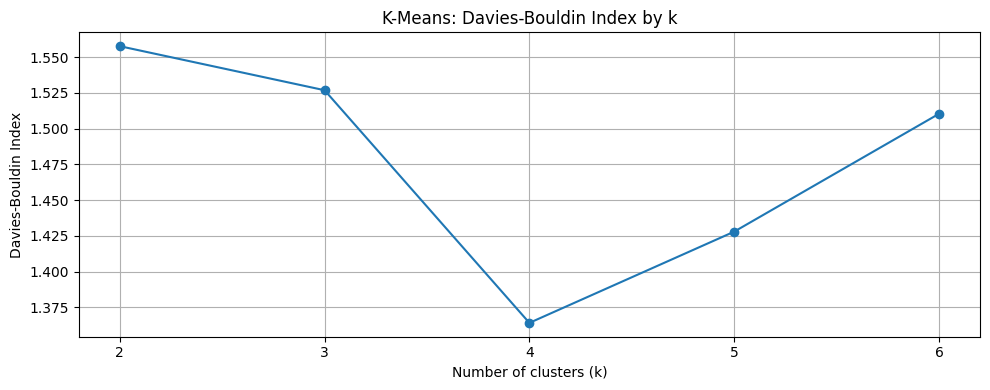

In [19]:
# visualising the two evaluation metrics
plt.figure(figsize=(10, 4))
plt.plot(k_results_df["k"], k_results_df["Silhouette Score"], marker="o")
plt.title("K-Means: Silhouette Score by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhoutte Score")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(k_results_df["k"], k_results_df["Davies-Bouldin Index"], marker="o")
plt.title("K-Means: Davies-Bouldin Index by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Davies-Bouldin Index")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
plt.show()

### Final comparison of k values using the full dataset

I first tested k from 2 to 6 on a sample of 5,000 rows. this made the initial comparison faster. Here, I repeat the analysis for k = 2, 3 and 4 using all 17379 rows. The scores are slightly differen because the amount of data is different.

With the full dataset, k=2 has the highest Silhouette Score (0.248296), while k=4 has the lowest Davies-Bouldin Index (1.371892). Moving from k=2 to k=4 reduces the Silhouette Score by about 3.9%, but it also reduces the Davies-Bouldin Index by about 11.6%.

I chose k=4 because the Silhouette result stays relatively close to the best score, while the Davies-Bouldin result improves. I also wanted to see wheter four groups could describe demand in more detail. This is a choice based on the two measures and the purpose of the analysis, rather than a claim that four cluster are always the best option.

In [20]:
# comparing K-means solutions for k=2, 3 and 4 on the full dataset
# the full data scores are used here for the final comparison
candidate_k = [2, 3, 4]
candidate_results = []

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    candidate_results.append({
        "k": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels), 
        "Smallest cluster size": pd.Series(labels).value_counts().min(),
        "Largest cluster size": pd.Series(labels).value_counts().max()
    })

candidate_results_df = pd.DataFrame(candidate_results)
display(candidate_results_df)

,k,Silhouette Score,Davies-Bouldin Index,Smallest cluster size,Largest cluster size
0,2,0.248296,1.551062,7924,9455
1,3,0.241193,1.530436,4935,6385
2,4,0.238698,1.371892,3279,5992


In [21]:
# multi-criteria decision: k=4 has a Silhouette Score close to the maximum and the lowest Davies-Bouldin
# Indez among the tested values.
# This is a reasoned modelling choice, not proof of a universally optimal k.
chosen_k = 4

print("Selected number of clusters (multi-citeria decision):", chosen_k)
print("Reason: near-maximum Silhouette Score and minumum Davies-Bouldin Index.", chosen_k)

Selected number of clusters (multi-citeria decision): 4
Reason: near-maximum Silhouette Score and minumum Davies-Bouldin Index. 4


## 6. Comparing K-Means and Agglomerative Clustering

I compared both methods using the same five standardised variables and k=4. This keeps the comparison consistent. K-Means forms groups around their centres, while Agglomerative Clustering starts with observations and gradually joins them into groups.

K-Means achieved a Silhouette Score of 0.238698 and Davies-Bouldin Index of 1.371892.
Agglomerative Clustering achieved 0.156832 and 1.766255. K-Means therefore performed better on both measures in this comparison.

Even so, the Silhouette results suggest that the groups overlap. I would use them to ecplore local patterns, rather than treating them as entirely distinct customer types or hours.


In [22]:
from sklearn.cluster import AgglomerativeClustering

#fitting K-means using the selected k
kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
data["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

#fitting Agglomerative using the selected k and features
agg = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
data["agg_cluster"] = agg.fit_predict(X_scaled)

print("Selected number of clusters (k):", chosen_k)

print("\nK-Means cluster sizes:")
print(data["kmeans_cluster"].value_counts().sort_index())

print("\nAgglomerative cluster sizes:")
print(data["agg_cluster"].value_counts().sort_index())

Selected number of clusters (k): 4

K-Means cluster sizes:
kmeans_cluster
0    5992
1    3517
2    4591
3    3279
Name: count, dtype: int64

Agglomerative cluster sizes:
agg_cluster
0    7052
1    4287
2    3732
3    2308
Name: count, dtype: int64


In [23]:
#calculating evaluation metrics for both algorithms
clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Silhouette Score": silhouette_score(X_scaled, data["kmeans_cluster"]),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, data["kmeans_cluster"])
    },
    {
     "Algorithm": "Agglomerative Clustering",
        "Silhouette Score": silhouette_score(X_scaled, data["agg_cluster"]),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, data["agg_cluster"])
    }
])
display(clustering_comparison)

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.238698,1.371892
1,Agglomerative Clustering,0.156832,1.766255


In [24]:
#summarising original feature values by k-means cluster
kmeans_profile = data.groupby("kmeans_cluster")[cluster_features].mean().round(3)
display(kmeans_profile)

#summarising original feature values by agglomerative cluster
agg_profile = data.groupby("agg_cluster")[cluster_features].mean().round(3)
display(agg_profile)

,hr,temp,hum,windspeed,cnt
kmeans_cluster,,,,,
0,4.471,0.459,0.766,0.135,66.923
1,12.357,0.344,0.463,0.312,144.366
2,14.490,0.684,0.507,0.200,405.551
3,19.488,0.468,0.718,0.147,159.212


,hr,temp,hum,windspeed,cnt
agg_cluster,,,,,
0,14.621,0.636,0.570,0.203,343.011
1,4.599,0.485,0.782,0.103,57.575
2,17.530,0.352,0.546,0.221,142.879
3,5.386,0.329,0.647,0.262,40.605


### Understanding the four clusters

The cluster profiles show some clear differences. Cluster 0 mainly represents early hours with low demand (about 67 rentals per hour). Cluster 1 has an average hour around midday and about 144 rentals; over half of its records are from season 1. Cluster 2 has the highest average demand (about 406 rentals), mainly in the afternoon, and almost half of its records are from season 3. Cluster 3 is more common in the evening, with about 159 rentals on average.

These descriptions are based on averages, so not every record in a cluster follows the same pattern. The cluster labels are just numbers. Also, hour is treated as a normal numeric feature, even though 23:00 and 00:00 are close in real life.


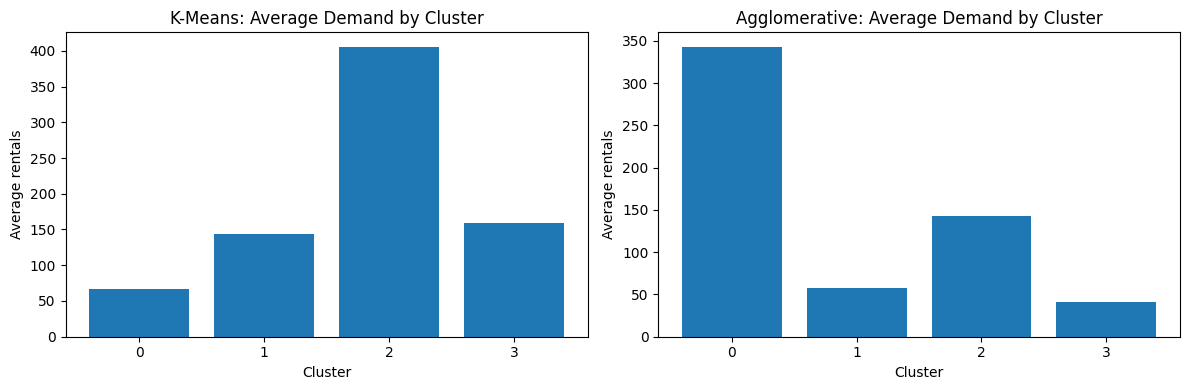

In [25]:
#visualising average demand ny cluster for each algorithm
kmeans_demand = data.groupby("kmeans_cluster")["cnt"].mean()
agg_demand = data.groupby("agg_cluster")["cnt"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(kmeans_demand.index.astype(str), kmeans_demand.values)
axes[0].set_title("K-Means: Average Demand by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average rentals")

axes[1].bar(agg_demand.index.astype(str), agg_demand.values)
axes[1].set_title("Agglomerative: Average Demand by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average rentals")

plt.tight_layout()
plt.show()

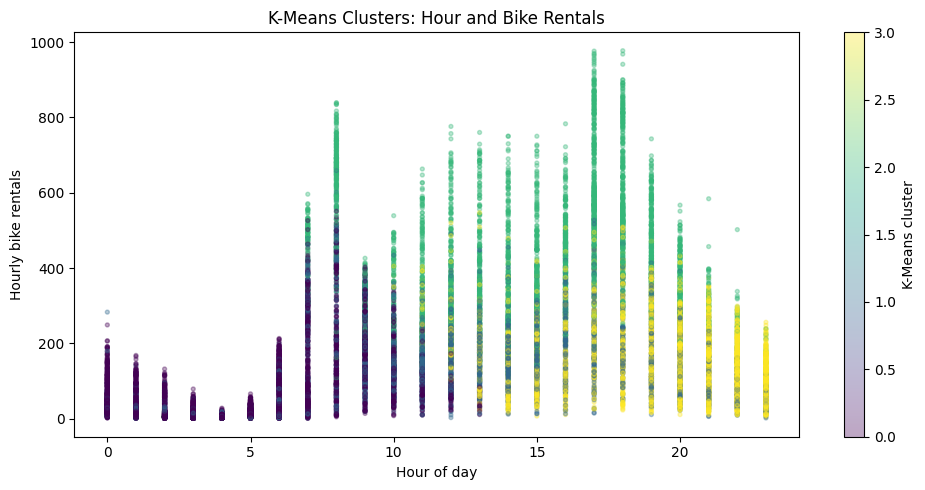

In [26]:
#visualising the K-means clusters using two original variables
plt.figure(figsize=(10, 5))
plt.scatter(data["hr"], data["cnt"], c=data["kmeans_cluster"], cmap="viridis", s=8, alpha=0.35)
plt.title('K-Means Clusters: Hour and Bike Rentals')
plt.xlabel('Hour of day')
plt.ylabel('Hourly bike rentals')
plt.colorbar(label='K-Means cluster')
plt.tight_layout()
plt.show()

### Looking at the cluster distribution

This scatter plot shows the observations by hour and rental count, coloured by their K-Means group. I can see where the groups are concentrated and where they overlap. This is only a two-variable view of clusters built from five variables, so it does not show all the information used by the model.

In [27]:
# Describe clusters using variables not used to build them
extra_profile = data.groupby("kmeans_cluster").agg(
    observations=("cnt", "size"),
    workingday_share=("workingday", "mean"),
    average_rentals=("cnt", "mean")
).round(3)
print("Working-day share: 1 means a working day")
display(extra_profile)
print("Season distribution within each cluster (row percentages):")
display((pd.crosstab(data["kmeans_cluster"], data["season"], normalize="index") * 100).round(1))
print("Weather distribution within each cluster (row percentages):")
display((pd.crosstab(data["kmeans_cluster"], data["weathersit"], normalize="index") * 100).round(1))

Working-day share: 1 means a working day


,observations,workingday_share,average_rentals
kmeans_cluster,,,
0,5992,0.674,66.923
1,3517,0.665,144.366
2,4591,0.710,405.551
3,3279,0.680,159.212


Season distribution within each cluster (row percentages):


season,1,2,3,4
kmeans_cluster,,,,
0,22.1,25.6,25.8,26.5
1,54.4,20.2,1.8,23.6
2,4.0,30.3,49.3,16.5
3,25.0,23.5,19.1,32.4


Weather distribution within each cluster (row percentages):


weathersit,1,2,3,4
kmeans_cluster,,,,
0,58.6,31.0,10.4,0.0
1,73.7,21.5,4.8,0.0
2,78.7,18.9,2.4,0.0
3,51.7,32.4,15.8,0.1


### Checking the business meaning of the clusters

I checked workingday, season and weathersit after building the clusters. These variables were not used to create the groups, so they help me understand what the groups represent.

The working-day share is quite similar across the four clusters: 67.4%, 66.5%, 71.0% and 68.0%. This suggests that the clusters do not clearly separate commuting days from non-working days. The seasonal profiles are more different. For example, 54.4% of cluster 1 comes from season 1, while 49.3% of cluster 2 comes from season 3.

This makes the clusters useful for describing patterns in the dataset, but not for claiming that they identify separate customer types or explain the causes of demand.

## 7. Time-series preparation - daily rental demand

For forecasting, I added together the hourly rentals for each date. This produces a daily series that is easier to study with ARIMA and SARIMA.

As the data cover only to years, I should considerate being caregful when discussing longer-term patterns.

In [28]:
# aggregating hourly rentals into daily totals
daily = data.groupby("dteday", as_index=True)["cnt"].sum().sort_index()

#creating a complete daily date index and identifying any missing dates
full_date_index = pd.date_range(start=daily.index.min(), end=daily.index.max(), freq="D")
daily = daily.reindex(full_date_index)
daily.index.name = "dteday"

print("Daily observations expected:", len(daily))
print("Missing daily values after reindexing:", daily.isnull().sum())

if daily.isnull().sum() > 0:
    print("Missing dates detected.")
else:
    print("Daily series has no missing dates.")

display(daily.head())
display(daily.tail())
    

Daily observations expected: 731
Missing daily values after reindexing: 0
Daily series has no missing dates.


dteday
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Freq: D, Name: cnt, dtype: int64

dteday
2012-12-27    2114
2012-12-28    3095
2012-12-29    1341
2012-12-30    1796
2012-12-31    2729
Freq: D, Name: cnt, dtype: int64

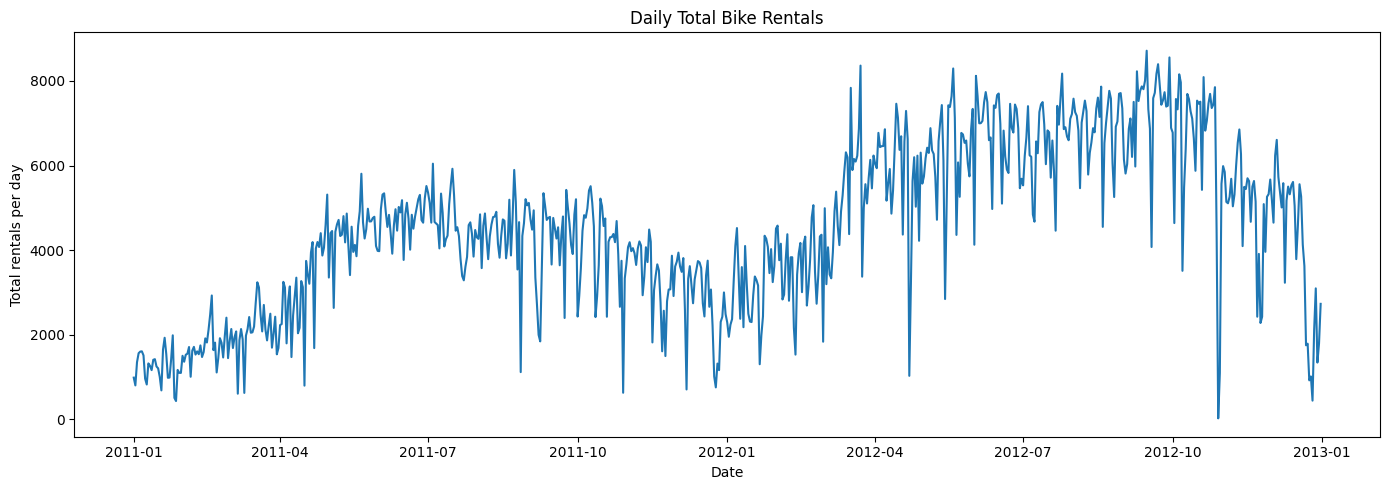

In [29]:
# plotting daily demand
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values)
plt.title("Daily Total Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Total rentals per day")
plt.tight_layout()
plt.show()

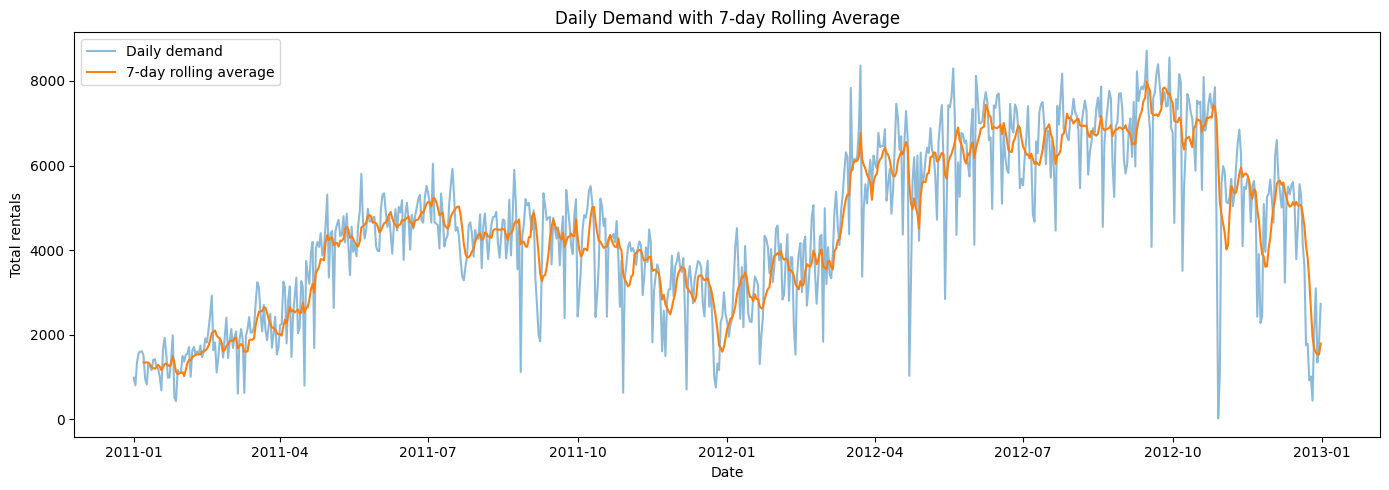

In [30]:
#plotting weekly rolling average to make the borader movement eadsier to see
daily_rolling = daily.rolling(window=7).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.5, label="Daily demand")
plt.plot(daily_rolling.index, daily_rolling.values, label="7-day rolling average")
plt.title("Daily Demand with 7-day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

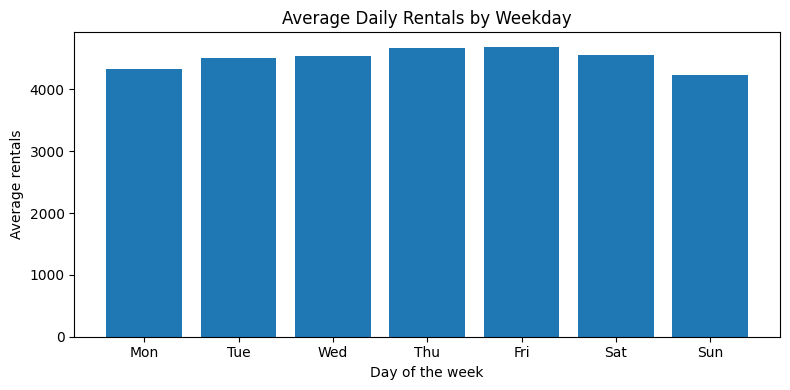

In [31]:
#comparing average demand by weekday
daily_frame = daily.to_frame(name="cnt")
daily_frame["weekday"] = daily_frame.index.dayofweek

daily_weekday_profile = daily_frame.groupby("weekday")["cnt"].mean()


plt.figure(figsize=(8, 4))
plt.bar(daily_weekday_profile.index, daily_weekday_profile.values)
plt.title("Average Daily Rentals by Weekday")
plt.xlabel("Day of the week")
plt.ylabel("Average rentals")
plt.xticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.tight_layout()
plt.show()


In [32]:
#exploring yearly averages and the lowest-demand days
annual_daily_average = daily.groupby(daily.index.year).mean()
print("Average daily rentals by year:")
display(annual_daily_average.round(1))
print("Change from 2011 to 2012 (%):", round((annual_daily_average.loc[2012] / annual_daily_average.loc[2011] - 1) * 100, 1))
print("Five lowest-demand days:")
display(daily.nsmallest(5))

#checking recorded weather conditions on the lowest-demand daus
lowest_dates = daily.nsmallest(5).index
weather_low_days = data[data["dteday"].isin(lowest_dates)].groupby("dteday").agg(
    daily_rentals = ("cnt", "sum"),
    worst_recorded_weather_code = ("weathersit", "max"),
    mean_temperature=("temp", "mean")
)
display(weather_low_days)

Average daily rentals by year:


dteday
2011    3405.8
2012    5599.9
Name: cnt, dtype: float64

Change from 2011 to 2012 (%): 64.4
Five lowest-demand days:


dteday
2012-10-29     22
2011-01-27    431
2012-12-26    441
2011-01-26    506
2011-03-06    605
Name: cnt, dtype: int64

,daily_rentals,worst_recorded_weather_code,mean_temperature
dteday,,,
2011-01-26,506,4,0.217500
2011-01-27,431,1,0.195000
2011-03-06,605,3,0.376522
2012-10-29,22,3,0.440000
2012-12-26,441,3,0.243333


### Trend, seasonality and unusal days

Daily data showed a significant increase in average demand between the two years: approximately 3,406 rentals per day in 2011, compared to 5,600 in 2012—a growth of 64.4%. The charts also reveal that demand fluctuates throughout the year, reaching higher levels during warmer periods and lower levels during colder ones. The chart broken down by day of the week also allows for the observation of short-term weekly patterns.

An outlier occurs on October 29, 2012, when only 22 rentals were recorded—a figure well below the 2012 daily average. The dataset shows a weather code of 3 for that date, but this information alone is insufficient to determine the cause of this drop. Other dates with low demand include January 27, 2011 (431 rentals) and December 26, 2012 (441 rentals).

I checked what happened on October 29, 2012 and found that Hurricane Sandy reached the US East Coast on the same day (National Hurricane Center, 2012). This could help explain the unusually low demand, as severe weather can affect people's travel plans and outdoor activities. However, I cannot confirm that the storm was the only reason for the drop in rentals.

This was also an important observation for the forecasting analysis because such a low value can have a large impact on percentage errors.

##  7.1 Checking stationarity

I used the Augmented Dickey-Fuller (ADF) test to help me check whether the daily series is stationary. The p-value was 0.3427, which is above 0.05. This means I cannot reject the test's unit=root hypothesis at the 5% level.

It doesnt prove that the series is non-stationary, but it gives me a reason to explore differencing. I also looked at the time-series plots and the ACF/PACF graphs when choosing model parameters.

In [33]:
from statsmodels.tsa.stattools import adfuller

# running the ADF test on the original daily series
adf_result = adfuller(daily.dropna())

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical values:", adf_result[4])


ADF statistic: -1.8774481444374291
p-value: 0.3427434403392198
Critical values: {'1%': np.float64(-3.439503230053971), '5%': np.float64(-2.8655794463678346), '10%': np.float64(-2.5689210707289982)}


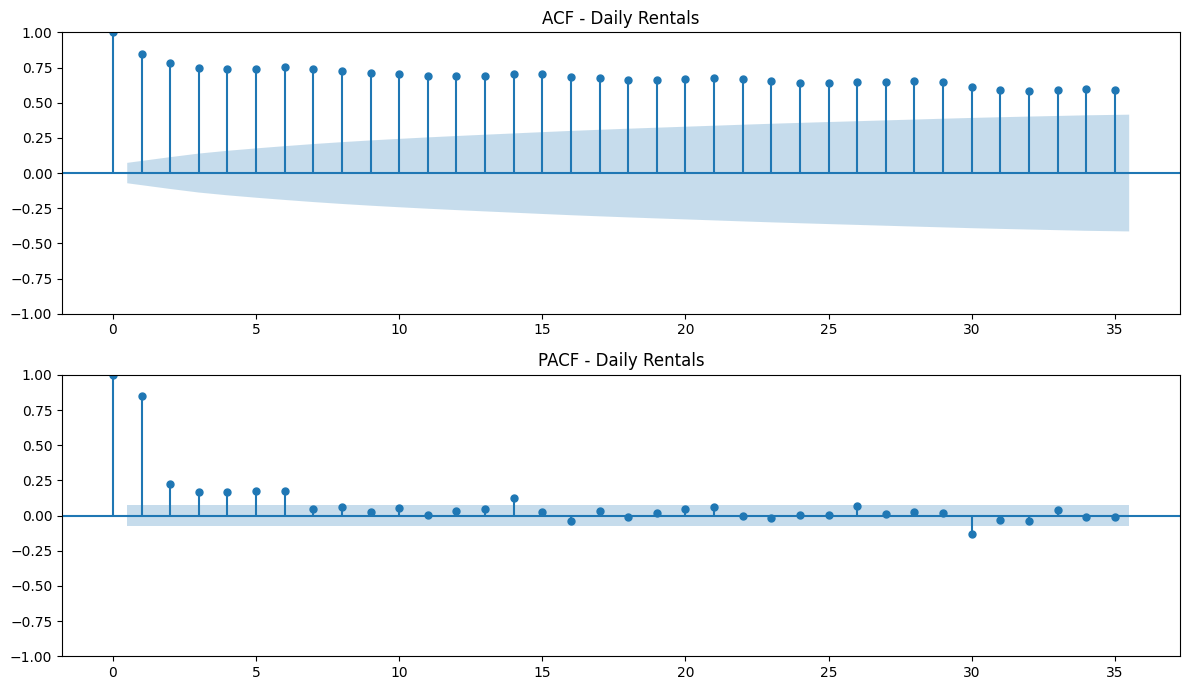

In [34]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#inpecting autocorrelation and partial autocorrelation
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(daily.dropna(), lags=35, ax=axes[0])
axes[0].set_title("ACF - Daily Rentals")

plot_pacf(daily.dropna(), lags=35, ax=axes[1], method="ywm")
axes[1].set_title("PACF - Daily Rentals")

plt.tight_layout()
plt.show()

First difference - ADF p-value: 0.0
First + weekly difference - ADF p-value: 0.0


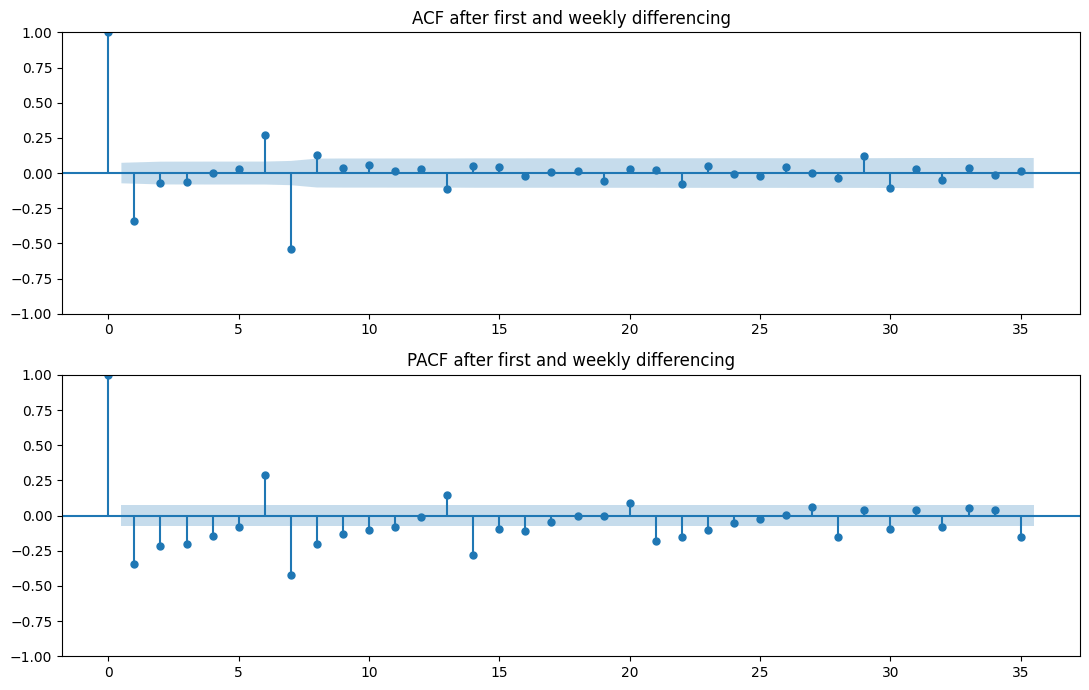

In [35]:
# Check stationarity and correlations after first and weekly differencing
first_difference = daily.diff().dropna()
seasonal_difference = first_difference.diff(7).dropna()
for name, series in [("First difference", first_difference), ("First + weekly difference", seasonal_difference)]:
    result = adfuller(series)
    print(name, "- ADF p-value:", round(result[1], 5))

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(seasonal_difference, lags=35, ax=axes[0])
axes[0].set_title("ACF after first and weekly differencing")
plot_pacf(seasonal_difference, lags=35, ax=axes[1], method="ywm")
axes[1].set_title("PACF after first and weekly differencing")
plt.tight_layout()
plt.show()

### What differencing changes

The original daily series had an ADF p-value of 0.3427, so I could not reject the unit-root hypothesis at the 5% level. After first differencing, the reported ADF p-value was close to zero. It was also close to zero after combining first and weekly differencing. This provides evidence against a unit root in the transformed series.

I also looked at the ACF and PACF after differencing to understand the remaining correlations. I used a weekly seasonal period of seven days as a practical choice for daily data, not because one graph proved that seven days was the only possible seasonal pattern.

## 8. Training, validation and test periods

I kept the dates in order because a real forecast can not use information from the future. I used the 80% of daily records for a model development and the final 20% for testing.

I compared SARIMA candidates on a validarion period within the training data. The final test period is used only after choosing the model.

Training obervations: 584
Testint observations: 147
Training period: 2011-01-01 00:00:00 to 2012-08-06 00:00:00
Testint period: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


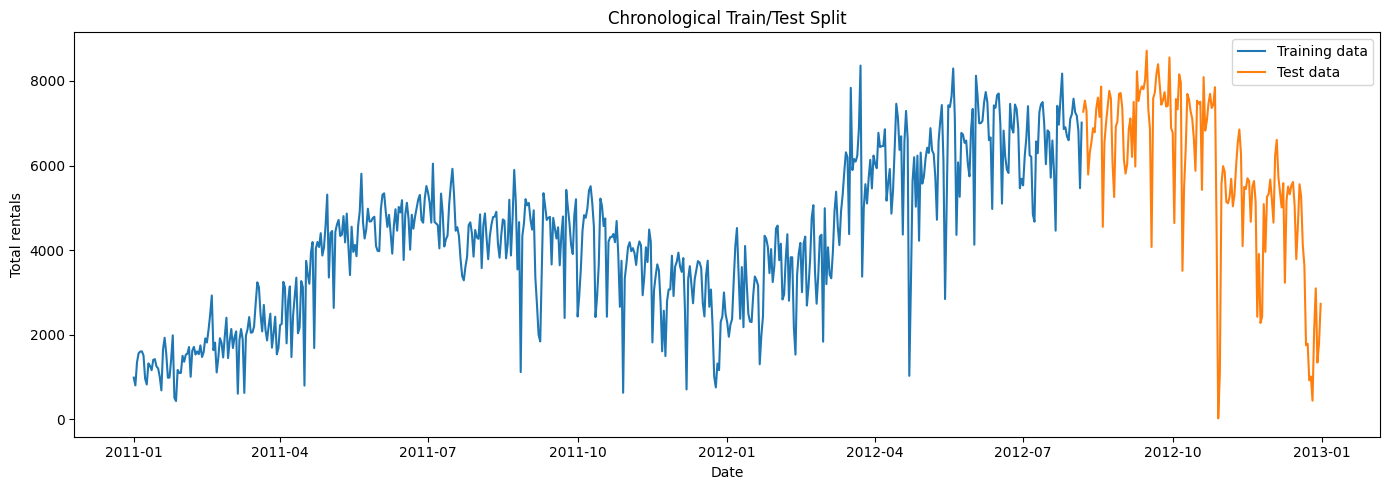

In [36]:
#spliting the daily series chronologically
split_point = int(len(daily)*0.80)

train = daily.iloc[:split_point]
test = daily.iloc[split_point:]

print("Training obervations:", len(train))
print("Testint observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testint period:", test.index.min(), "to", test.index.max())

plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training data")
plt.plot(test.index, test.values, label="Test data")
plt.title("Chronological Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Choosing the SARIMA model

SARIMA uses the parameters (p, d, q) for the non-seasonal part and (P, D, Q, s) for the seasonal part. I explored a weekly seasonal period (s = 7) because the observations are daily and bike use can vary between weekdays and weekends. This is a practical hypothesis, not proof of a strong weekly peak in the ACF.

The original ADF test gave a p-value of 0.3427, so I investigated first differencing (d = 1). I also tested seasonal differencing (D = 1) and looked at ACF/PACF plots. The next check examines the differenced series directly. I then compared four candidate models using validation RMSE, without using the final test period for selection. The chosen model was SARIMA(1,1,1) × (1,1,1,7). It was the best of the four candidates tested, not necessarily the best possible SARIMA model.

In [37]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

#comparing a small set of SARIMA candidates using a validation split taken from the training periodo.
#the finl test set remains untouched until the final evaluation.
validation_split = int(len(train)*0.80)
subtrain = train.iloc[:validation_split]
validation = train.iloc[validation_split:]

sarima_candidates = [
    ((1, 1, 1), (1, 1, 1, 7)),
    ((1, 1, 0), (1, 1, 0, 7)),
    ((2, 1, 1), (1, 1, 0, 7)),
    ((1, 0, 1), (1, 1, 0, 7)),
]

sarima_validation_results = []

for candidate_order, candidate_seasonal_order in sarima_candidates:
    try:
        candidate_model = SARIMAX(
            subtrain,
            order=candidate_order,
            seasonal_order=candidate_seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        candidate_fit = candidate_model.fit(disp=False)
        candidate_forecast = candidate_fit.get_forecast(steps=len(validation)).predicted_mean
        candidate_forecast.index = validation.index

        candidate_mae = mean_absolute_error(validation, candidate_forecast)
        candidate_rmse = mean_squared_error(validation, candidate_forecast)** 0.5

        sarima_validation_results.append({
            "order": candidate_order,
            "seasonal_order": candidate_seasonal_order,
            "Validation MAE": candidate_mae,
            "Validation RMSE": candidate_rmse,
            "Converged": candidate_fit.mle_retvals.get("converged", None)
        })
    except Exception as error:
        print("Candidate failed:", candidate_order, candidate_seasonal_order, error)

sarima_validation_df = pd.DataFrame(sarima_validation_results)
display(sarima_validation_df)

best_candidate_row = sarima_validation_df.loc[sarima_validation_df["Validation RMSE"].idxmin()]
order = best_candidate_row["order"]
seasonal_order = best_candidate_row["seasonal_order"]

print("Selected order:", order)
print("Selected seasonal_order:", seasonal_order)
print("Selection rule: lowest RMSE on the validation segment inside the training period.")

#refiting the selected configuration on the complete training period
sarima_model = SARIMAX(
    train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)
sarima_fit = sarima_model.fit(disp=False)
print(sarima_fit.summary())

,order,seasonal_order,Validation MAE,Validation RMSE,Converged
0,"(1, 1, 1)","(1, 1, 1, 7)",847.200771,1151.983731,True
1,"(1, 1, 0)","(1, 1, 0, 7)",5642.670217,6397.565153,True
2,"(2, 1, 1)","(1, 1, 0, 7)",1248.160528,1625.584215,True
3,"(1, 0, 1)","(1, 1, 0, 7)",1034.781178,1254.029402,True


Selected order: (1, 1, 1)
Selected seasonal_order: (1, 1, 1, 7)
Selection rule: lowest RMSE on the validation segment inside the training period.
                                     SARIMAX Results                                     
Dep. Variable:                               cnt   No. Observations:                  584
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -4638.789
Date:                           Fri, 30 Oct 2026   AIC                           9287.578
Time:                                   16:03:58   BIC                           9309.280
Sample:                               01-01-2011   HQIC                          9296.047
                                    - 08-06-2012                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------

Selected model AIC: 9287.58
Model converged: True
Seasonal MA parameter (if fitted):
ma.S.L7   -1.035119
dtype: float64


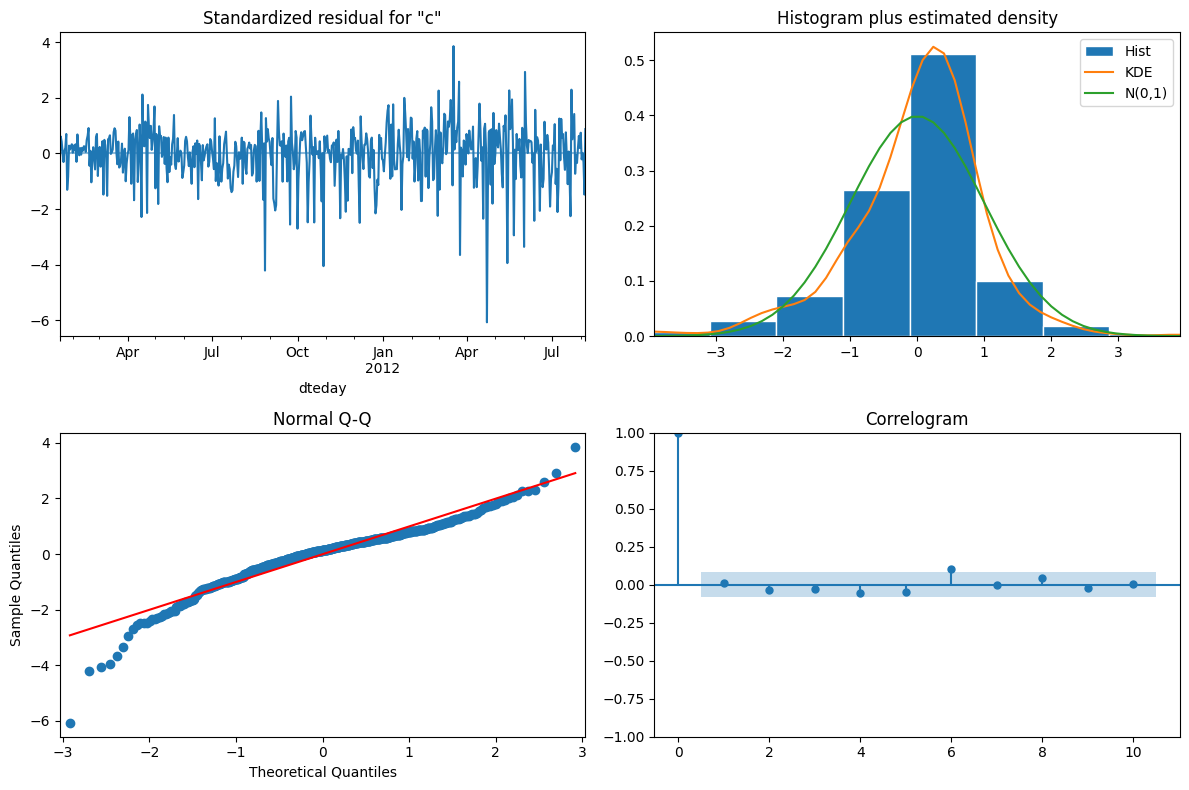

In [38]:
# Basic diagnostic plots for the selected SARIMA fit
print("Selected model AIC:", round(sarima_fit.aic, 2))
print("Model converged:", sarima_fit.mle_retvals.get("converged", None))
print("Seasonal MA parameter (if fitted):")
print(sarima_fit.params[[x for x in sarima_fit.params.index if "ma.S" in x]])
sarima_fit.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

### Checking the fitted model

The selected SARIMA model converged, but the diagnostic results show some limitations. Its seasonal MA coefficient was approximately -1.035, which raises a concern about invertibility. The Jarque–Bera statistic was about 493.66, with a very small p-value, so the residuals do not appear normally distributed. The reported kurtosis was 7.08, suggesting heavy tails.

I used these diagnostics to check the model rather than assuming that convergence meant a good forecast. The coefficient alone does not prove over-differencing, and the diagnostics do not tell me one exact reason for the test errors.

## 10. Forecasting and checking accuracy

I used the selected SARIMA model to predict the daily rentals in the test period. I compared the predictions with the actual values using MAE, RMSE and MAPE. Lower errors mean more accurate forecasts.

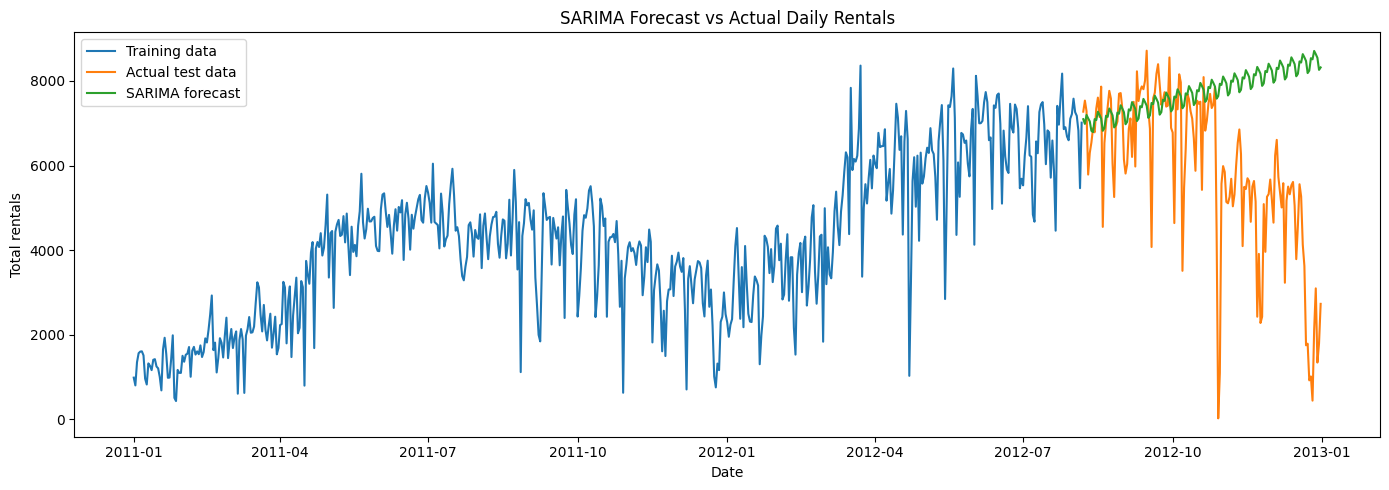

In [39]:
#forecast the test period
forecast_result = sarima_fit.get_forecast(steps=len(test))
forecast = forecast_result.predicted_mean

#aligning forecast dates with the test data
forecast.index = test.index

#ploting actual and predicted demand
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training data")
plt.plot(test.index, test.values, label="Actual test data")
plt.plot(forecast.index, forecast.values, label="SARIMA forecast")
plt.title("SARIMA Forecast vs Actual Daily Rentals")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
#calculating forecasting errors
mae = mean_absolute_error(test, forecast)
mse = mean_squared_error(test, forecast)
rmse = mse** 0.5

if (test != 0).all():
    mape = (abs((test - forecast) / test)).mean() * 100
else:
    mape = None

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
if mape is not None:
    print("MAPE (%):", round(mape, 3))
else:
    print("MAPE not calculated because at least one actual value is zero.")

MAE: 2034.394
RMSE: 2858.741
MAPE (%): 310.008


### 10.1 Looking at forecast errors

I calculated each residuals as the actual value minus the predicted value. A positive residual means the model predicted too little; a negative residual means it predicted too much. Looking at the residuals helped me see whether the errors follow a pattern.

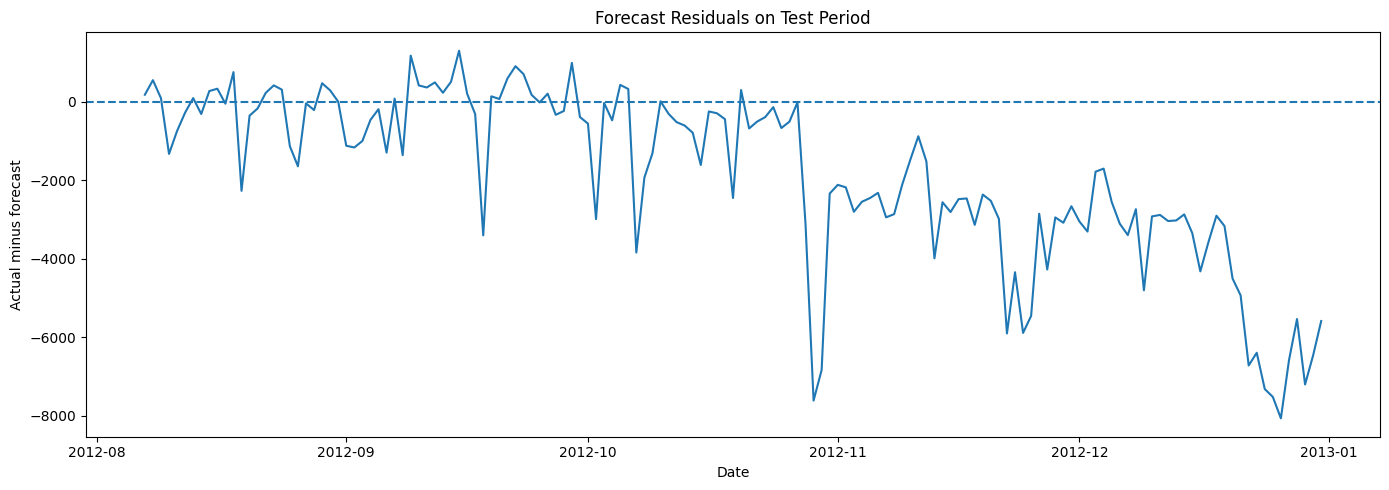

Mean test residual: -1849.164


In [41]:
#calculate and plot test residuals
residuals = test - forecast

plt.figure(figsize=(14, 5))
plt.plot(residuals.index, residuals.values)
plt.axhline(0, linestyle="--")
plt.title("Forecast Residuals on Test Period")
plt.xlabel("Date")
plt.ylabel("Actual minus forecast")
plt.tight_layout()
plt.show()

print("Mean test residual:", round(residuals.mean(), 3))

In [42]:
#investigating whether very low-demand days affect percentage errors
absolute_percentage_errors = (abs(test - forecast) / test.replace(0, float("nan")))*100
print("Highest percentage-error dates:")
display(absolute_percentage_errors.sort_values(ascending=False).head(5))
print("Lowest actual daily rentals in the test period:")
display(test.nsmallest(5))

#sensitivity check only: it doenst replace the original MAPE
if pd.Timestamp("2012-10-29") in test.index:
    mape_without_date = absolute_percentage_errors.drop(pd.Timestamp("2012-10-29")).mean()
    print("MAPE excluding 29 Oct 2012 (sensitivity check only):", round(mape_without_date, 2))
else:
    print("29 Oct 2012 is not in this test period.")

Highest percentage-error dates:


dteday
2012-10-29    34619.685886
2012-12-26     1829.824901
2012-12-24      795.998837
2012-12-25      742.738304
2012-10-30      623.729983
dtype: float64

Lowest actual daily rentals in the test period:


dteday
2012-10-29      22
2012-12-26     441
2012-12-24     920
2012-12-25    1013
2012-10-30    1096
Name: cnt, dtype: int64

MAPE excluding 29 Oct 2012 (sensitivity check only): 75.01


### Understanding the forecast errors

The SARIMA forecast had a residual of around -1,849 rentals meaning that the SARIMA forecast usually predicted more rentals than were actually seen during the test period. One possible reason is that a model that was fitted before August 2012 could not keep up with the drop in demand. This is a possible explanation suggested by the plots; the results alone do not prove it.

The test period covers 147 days. That is a forecasting horizon especially because the model was not updated with new actual observations. This may also make the task more difficult. A shorter forecasting horizon could be tried in work.

The MAPE was 310.01%. It was strongly affected by days that had low actual demand. For example on 29 October 2012 there were 22 rentals. When I removed that date from the MAPE calculation as a sensitivity check the MAPE dropped to 75.01%. I kept the result because removing an unusual day does not solve the forecasting problem. The MAE and RMSE are more useful, for comparing the models here.

## 11. Comparing SARIMA with a simple forecast

I also tested a seasonal-naive forecast. It repeats the weekly pattern seen in the training data. For a fair comparison with the multistep SARIMA forecast, it uses its own earlier predictions after the first seven test days, instead of looking actual values from later in the test period.

In [43]:
#fixed-origin seasonal-naive forecast for a fair comparison with SARIMA.
#forecast each test day using the value from 7days earlier.
#Once the forecast moves into the test period, used earlier baseline forecasts, not actual
#test observations. This keeps the entire test horizon forecast-based.

baseline_values = []

for i, date in enumerate(test.index):
    if i < 7:
        predicted_value = train.iloc[-7 + i]
    else:
        predicted_value = baseline_values[i - 7]

    baseline_values.append(predicted_value)

baseline = pd.Series(baseline_values, index=test.index)

baseline_mae = mean_absolute_error(test, baseline)
baseline_rmse = mean_squared_error(test, baseline) ** 0.5

print("Fixed-origin seasonal-naive MAE:", round(baseline_mae, 3))
print("Fixed-origin seasonal-naive RMSE:", round(baseline_rmse, 3))
print("SARIMA MAE:", round(mae, 3))
print("SARIMA RMSE:", round(rmse, 3))

Fixed-origin seasonal-naive MAE: 1506.095
Fixed-origin seasonal-naive RMSE: 2136.774
SARIMA MAE: 2034.394
SARIMA RMSE: 2858.741


### How the seasonal-naive comparison works

The seasonal-naive forecast repeats the weekly pattern available at the end of the training period. After seven days, it uses its own earlier predictions to continue forecasting. It doesn't use actual test-period rentals to predict later test days.

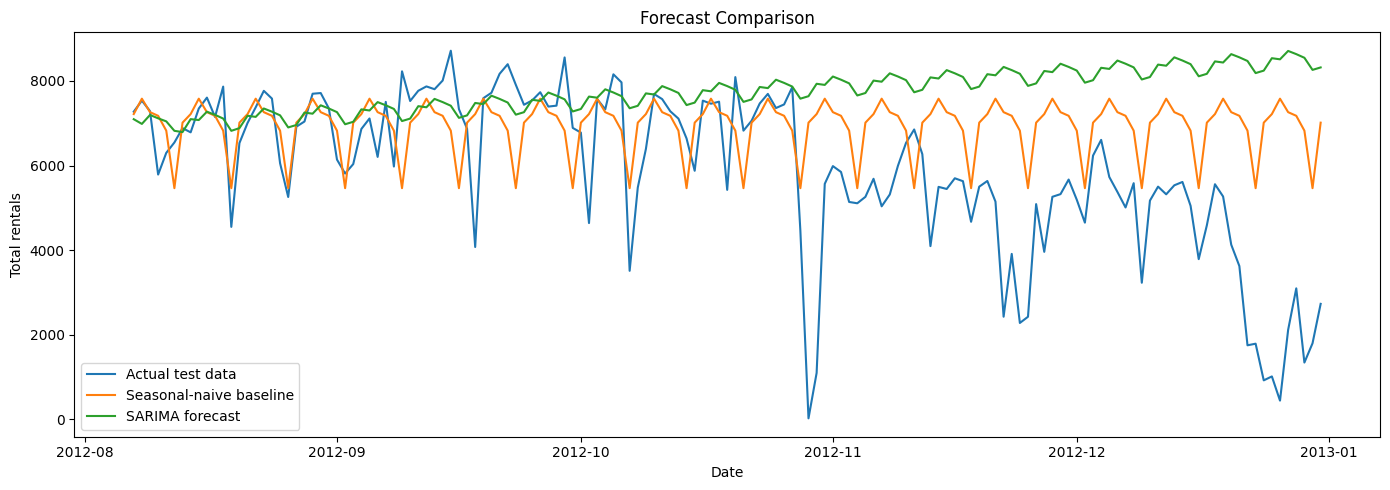

In [44]:
#ploting baseline and SARIMA forecasts against the actual test data
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual test data")
plt.plot(baseline.index, baseline.values, label="Seasonal-naive baseline")
plt.plot(forecast.index, forecast.values, label="SARIMA forecast")
plt.title("Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Main results and model comparison

The codes below show the main clustering and forecasting results. I used these values, together with the charts, to decide which methods worked better and what the limitations are.

In [45]:
#summarising clustering and forecasting metrics
forecast_comparison = pd.DataFrame([
    {"Model": "Seasonal-naive baseline", "MAE": baseline_mae, "RMSE": baseline_rmse},
    {"Model": "SARIMA", "MAE": mae, "RMSE": rmse}
])

print("Clustering comparison:")
display(clustering_comparison)

print("Forecast comparison:")
display(forecast_comparison)

Clustering comparison:


,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.238698,1.371892
1,Agglomerative Clustering,0.156832,1.766255


Forecast comparison:


,Model,MAE,RMSE
0,Seasonal-naive baseline,1506.095238,2136.774083
1,SARIMA,2034.393802,2858.740762


### Compating the models

This final comparison brougth the main model results together. For clustering, I looked at both scores rather than relying on one measure. For forecasting, I compared the errors of SARIMA with those of the simpler seasonal-naive model.

In [46]:
#identifying metric winners from the actual run
best_silhouette_row = clustering_comparison.loc[clustering_comparison["Silhouette Score"].idxmax()]
best_dbi_row = clustering_comparison.loc[clustering_comparison["Davies-Bouldin Index"].idxmin()]

print("Highest Silhouette Score:", best_silhouette_row["Algorithm"],
      "(", round(best_silhouette_row["Silhouette Score"], 4), ")")
print("Lowest Davies-Bouldin Index:", best_dbi_row["Algorithm"],
      "(", round(best_dbi_row['Davies-Bouldin Index'], 4), ")")

if best_silhouette_row["Algorithm"] == best_dbi_row["Algorithm"]:
    print("Both metrics favour the same algorithm on this run.")
else:
    print("The metrics favour different algorithms; discuss this disagreement.")

if mae < baseline_mae and rmse < baseline_rmse:
    print("SARIMA has lower MAE and RMSE than the seasonal-naive baseline on this test set.")
elif mae > baseline_mae and rmse > baseline_rmse:
    print("The seasonal-naive baseline has lower MAE and RMSE than SARIMA on this test set.")
else:
    print("The forecast metrics are mixed; compare MAE, RMSE, and the forecast plots.")

Highest Silhouette Score: K-Means ( 0.2387 )
Lowest Davies-Bouldin Index: K-Means ( 1.3719 )
Both metrics favour the same algorithm on this run.
The seasonal-naive baseline has lower MAE and RMSE than SARIMA on this test set.


### What the forecasting results showed

I chose SARIMA(1,1,1) × (1,1,1,7) because it had the lowest RMSE (1,151.98) when I compared four models during validation. However, the results were not as good when I tested it on the final dataset. SARIMA had an MAE of 2,034.39 and an RMSE of 2,858.74, while the seasonal-naive model had lower errors of 1,506.10 and 2,136.77.

I also noticed that SARIMA was predicting more bike rentals than actually happened, with an average residual of around -1,849. I think this might be because the model expected demand to stay high, even when it started to decrease. Another possible reason is that I was trying to predict 147 days without updating the model, which is quite a long period.

The MAPE was also very high, at around 310%. This may be partly because some days had very few rentals, making the percentage errors much bigger. For this reason, I think MAE and RMSE give a clearer picture of how well the models performed.

## 13. Method Limitations and Considerations

There are some limitations that I needed to consider when looking at my results.

For clustering, I first used a sample of 5,000 records to compare diffeerent values of k. After that, I used the full dataset to make my final decision. This is why the results in the two tables are slightly different. I also selected k=4 based on K-Means and then used the same number of clusters for Agglomerative Clustering. This made the comparison easier, but a different number of clusters might work better for each algotithm.

Another point is that the evaluation metrics didn't tell me everything about the clusters. Even though K-Means performed better, the groups still overlap. Also, because I included the numver of rentals as one of the variables, the clusters helped describe demand patterns, but they cannot be used directly to predict future rentals.

For forecasting, I only tested four SARIMA models, so there could be other configurations with better results. I also tried to predict 147 days without updating the model, which may have affected its accuracy. Finallt, the dataset covers 2011 and 2012, so the patterns might be different if I had used more recent data.

## 14. Conclusions

In this project, I was able to identify different bike-sharing demand patterns and use historical data to make predictions about future rentals.

For clustering, K-Means performed better than Agglomerative Clustering. I chose four clusters, which helped me understand how rental demand changes during different times of the day and under different conditions. One interesting result was that some groups had much higher demand than others. For a bike-sharing company, this information could be useful when planning bike availability and understanding busy periods.

For forecasting, the results were different from what I expected. I selected SARIMA because it performed best during validation, but when I tested it on the final period, the simpler seasonal-naive model gave more accurate predictions. I also noticed that SARIMA often predicted more rentals than actually happened, especially during periods when demand was decreasing.

I think this is one of the most important findings of my project. It showed me that using a more complex model does not always mean getting better results. It is important to compare different approaches and understand why a model makes errors.

In general, I achieved the main objectives of the project. I identified different demand patterns, compared clustering algorithms and tested how historical data could be used for forecasting. Although the predictions were not as accurate as I expected, the analysis helped me understand both the possibilities and the limitations of Machine Learning.

From a business perspective, I would use the clustering results to better understand demand and start with the seasonal-naive model for forecasting, while continuing to test ways to improve accuracy.

## 15. References

Davies, D.L. and Bouldin, D.W. (1979) 'A cluster separation measure', *IEEE Transactions on Pattern Analysis and Machine Intelligence*, PAMI-1(2), pp. 224–227.

Fanaee-T, H. (2013) *Bike Sharing* [Dataset]. UCI Machine Learning Repository. Available at: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset (Accessed: 15 October 2026).

Fanaee-T, H. and Gama, J. (2014) 'Event labeling combining ensemble detectors and background knowledge', *Progress in Artificial Intelligence*, 2(2–3), pp. 113–127.

National Hurricane Center (2012) Post-Tropical Cyclone Sandy: Tropical Cyclone Update, 29 October 2012. National Oceanic and Atmospheric Administration. Available at: NOAA — Hurricane Sandy, 29 October 2012 (Accessed: 29 October 2026).

Iqbal, M. (2026). Machine Learning.